# **Dataset**

O dataset MNIST é um conjunto de dados de dígitos manuscritos para o aprendizado de máquina e visão computacional. Ele é composto por:

* Imagens: 70.000 imagens em tons de cinza de dígitos manuscritos (0 a 9).
* Resolução: Cada imagem tem uma resolução de $28 \times 28$ pixels.
* Divisão: Tradicionalmente dividido em 60.000 imagens para treinamento e 10.000 imagens para teste.
* Classes: 10 classes distintas, representando os dígitos de 0 a 9.

O MNIST é ideal para começar a explorar algoritmos de classificação de imagens devido à sua simplicidade e clareza. Embora seja um problema relativamente "fácil" para modelos complexos de redes neurais (como as CNNs), apresenta desafios interessantes para modelos mais simples, como o Perceptron, permitindo uma compreensão clara das capacidades e limitações desses modelos.

In [1]:
from sklearn.datasets import load_digits
digits = load_digits()
print(digits.data.shape)

(1797, 64)


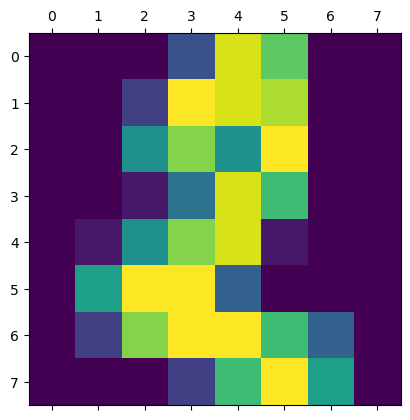

In [2]:
import matplotlib.pyplot as plt
plt.matshow(digits.images[2])
plt.show()

O Perceptron é a unidade básica de uma rede neural. Ele recebe múltiplas entradas, as pondera por pesos sinápticos, soma-as com um viés (bias) e aplica uma função de ativação para produzir uma saída.

Para aplicar o Perceptron ao dataset MNIST, cada imagem de $28 \times 28$ pixels precisa ser "achatada" (flattened) em um vetor de $28 \times 28 = 784$ pixels. Cada um desses 784 pixels se torna uma entrada ($x_j$) para o Perceptron.

In [3]:
from sklearn.datasets import load_digits
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1. Carregar o Dataset
print("Carregando o dataset Digits...")
X, y = load_digits(return_X_y=True)
print(f"Shape dos dados de entrada (X): {X.shape}") # (1797, 64) - 1797 amostras, 64 features (8x8 pixels)
print(f"Shape dos rótulos (y): {y.shape}") # (1797,)
print(f"Número de classes únicas: {len(set(y))}") # 10 classes (0 a 9)

# 2. Dividir os dados em conjuntos de treino e teste de forma mais robusta
# Usamos train_test_split para garantir que os dados sejam embaralhados e divididos aleatoriamente.
# O parâmetro 'stratify=y' garante que a proporção de classes seja a mesma nos conjuntos de treino e teste.
print("\nDividindo os dados em treino e teste...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Amostras de treino: {X_train.shape[0]}")
print(f"Amostras de teste: {X_test.shape[0]}")

# 3. Pré-processamento: Padronização dos dados
# A padronização é crucial para muitos modelos lineares e redes neurais, incluindo o Perceptron.
# Ela garante que todas as features (pixels) tenham média 0 e desvio padrão 1, o que ajuda na convergência.
print("\nPadronizando os dados...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Inicializar e Treinar o Modelo Perceptron
# O Perceptron do scikit-learn é um classificador linear que pode lidar com múltiplas classes.
# 'tol' é a tolerância para o critério de parada (quando a perda não melhora mais do que 'tol').
# 'random_state' garante a reprodutibilidade da inicialização dos pesos.
print("\nInicializando e treinando o modelo Perceptron...")
clf = Perceptron(tol=1e-3, random_state=0, verbose=False)
clf.fit(X_train_scaled, y_train)
print("Treinamento concluído.")


Carregando o dataset Digits...
Shape dos dados de entrada (X): (1797, 64)
Shape dos rótulos (y): (1797,)
Número de classes únicas: 10

Dividindo os dados em treino e teste...
Amostras de treino: 1437
Amostras de teste: 360

Padronizando os dados...

Inicializando e treinando o modelo Perceptron...
Treinamento concluído.


### **Treinamento e Avaliação**

1. **Divisão de Dados (train_test_split)**

O train_test_split (importado de sklearn.model_selection) embaralha os dados aleatoriamente antes de dividi-los.  

O parâmetro stratify=y é muito importante para problemas de classificação multi-classe. Ele garante que a proporção de cada classe seja a mesma nos conjuntos de treino e teste, evitando que um conjunto fique com poucas amostras de uma classe específica.  

O test_size=0.2 significa que 20% dos dados serão usados para teste e 80% para treino, uma divisão comum.  

O random_state=42 (ou qualquer outro número) garante que a divisão seja a mesma cada vez que você executa o código, tornando seus resultados reproduzíveis.  

2. **Pré-processamento (StandardScaler)**

O Perceptron, como muitos modelos lineares, é sensível à escala das features. Se os valores dos pixels variarem muito, as features com valores maiores podem dominar o processo de aprendizado.  
O StandardScaler (importado de sklearn.preprocessing) padroniza os dados, transformando-os para que tenham média zero e desvio padrão um. Isso ajuda o algoritmo de otimização a convergir mais rapidamente e, muitas vezes, melhora o desempenho do modelo.  
É crucial aplicar fit_transform no conjunto de treino e apenas transform no conjunto de teste para evitar vazamento de dados (data leakage).  

3. **Avaliação do Modelo**

Após treinar o modelo, é fundamental avaliar seu desempenho. A acurácia fornece uma métrica geral, enquanto o relatório de classificação oferece métricas mais detalhadas (precisão, recall, f1-score) para cada classe, o que é muito útil em problemas multi-classe para identificar se o modelo está tendo dificuldade com alguma classe específica.

O atributo clf.n_iter_ de um objeto Perceptron no scikit-learn representa o número real de iterações (epochs) que o otimizador realizou sobre os dados de treinamento até atingir a convergência ou o número máximo de iterações permitido.  

No atributo clf.fit(), o algoritmo do Perceptron começa a iterar sobre o conjunto de dados de treinamento, ajustando seus pesos. Ele continua fazendo isso até que uma das seguintes condições seja atendida:  

**Convergência:** A perda (erro) no conjunto de treinamento não melhora mais do que um certo limite (definido pelo parâmetro tol, que você configurou como 1e-3).  

**Número Máximo de Iterações:** O algoritmo atinge o número máximo de iterações permitido (definido pelo parâmetro max_iter, que por padrão é 1000 no Perceptron do scikit-learn).  

In [11]:
# 5. Avaliar o Modelo
print(f"Número de iterações (epochs) realizadas")
print(clf.n_iter_)
print("\nAvaliando o desempenho do modelo...")
y_pred = clf.predict(X_test_scaled)
print(y_pred) # predição de dados que não conhece

Número de iterações (epochs) realizadas
21

Avaliando o desempenho do modelo...
[5 2 8 6 7 3 6 2 6 5 0 5 9 3 4 4 2 4 9 9 6 3 8 1 2 5 6 0 3 4 6 7 2 6 6 6 8
 5 0 9 1 7 3 6 5 7 5 2 7 5 0 1 5 5 3 2 4 0 0 2 7 5 6 1 3 7 6 5 7 0 9 0 3 8
 1 5 7 2 3 5 4 3 2 7 9 6 1 9 0 1 2 9 4 8 1 2 7 8 4 2 6 9 3 7 3 9 6 9 1 0 9
 2 1 4 3 7 8 7 1 0 0 4 6 5 1 2 8 1 3 0 0 8 6 4 3 9 3 3 3 3 0 7 0 0 1 9 5 8
 1 5 0 6 6 6 6 1 1 7 6 7 7 8 7 3 6 5 9 0 3 8 0 9 8 1 9 5 9 5 8 9 9 7 9 1 9
 5 4 7 3 0 4 9 7 7 5 1 5 8 3 4 5 4 9 2 5 5 2 1 3 8 8 9 3 6 9 0 1 4 0 5 5 6
 6 7 4 3 8 4 2 0 7 9 2 8 4 8 4 2 4 0 0 0 2 6 7 0 4 5 2 2 9 0 4 6 2 2 3 9 2
 3 0 6 8 7 1 4 4 1 1 6 3 8 1 2 5 7 8 3 2 0 3 4 1 9 7 9 6 3 7 1 6 9 4 7 1 8
 1 3 0 5 3 4 3 9 3 5 4 7 4 1 5 1 5 0 8 8 4 2 3 8 4 1 2 0 1 1 4 4 5 7 5 0 3
 2 2 4 2 7 7 8 7 6 3 1 1 5 8 8 8 6 7 2 7 8 9 4 2 0 3 4]



*clf.score(X_train, y_train):* Calcula a precisão de treino (training accuracy). A precisão de treino indica o quão bem o modelo se ajustou aos dados que ele "viu" durante o treinamento. Mede o desempenho do modelo nos dados que ele usou para aprender.  

Um valor alto aqui é esperado, mas não é suficiente para garantir um bom modelo. Se a precisão de treino for muito alta (próxima de 100%) e a precisão de teste for significativamente mais baixa, isso é um forte indicativo de overfitting (o modelo "decorou" os dados de treino, incluindo o ruído, e não consegue generalizar bem).

*clf.score(X_test, y_test):* Calcula a precisão de teste (test accuracy). A precisão de teste é uma métrica muito mais importante, pois ela mede a capacidade do modelo de generalizar para dados novos e não vistos. Mede o desempenho do modelo em dados que ele nunca viu antes.  

É a métrica mais confiável para avaliar o quão bem o seu modelo funcionará no "mundo real". Se a precisão de teste for baixa, pode indicar underfitting (o modelo não aprendeu os padrões essenciais dos dados) ou que o modelo não está generalizando bem.

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo Perceptron: {accuracy:.4f}")

Acurácia do modelo Perceptron: 0.9333


In [13]:
clf.score(X_train_scaled, y_train) # precisão de treino

0.9749478079331941

In [14]:
clf.score(X_test_scaled, y_test) # precisão de teste

0.9333333333333333

In [15]:
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))


Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.81      0.83      0.82        36
           2       0.94      0.94      0.94        35
           3       0.93      1.00      0.96        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       0.97      0.92      0.94        36
           7       0.92      0.97      0.95        36
           8       0.91      0.83      0.87        35
           9       0.91      0.86      0.89        36

    accuracy                           0.93       360
   macro avg       0.93      0.93      0.93       360
weighted avg       0.93      0.93      0.93       360



In [16]:
print("--- Avaliação e Previsões no Conjunto de Dados Completo (Padronizado) ---")

# 1. Padronizar o conjunto de dados completo (X) usando o scaler já treinado.
# É crucial usar o mesmo scaler que foi ajustado nos dados de treino (X_train).
# Não usar o fit_transform, apenas transform, pois o scaler já aprendeu as estatísticas.
print("\nPadronizando o conjunto de dados completo para avaliação e previsão...")
X_full_scaled = scaler.transform(X)

# 2. Calcular a precisão do modelo no conjunto de dados completo padronizado.
# Isso mede o desempenho geral do modelo em todos os dados (treino e teste combinados),
# mas com a escala correta que o modelo espera.
accuracy_full_scaled = clf.score(X_full_scaled, y)
print(f"\nPrecisão do modelo no conjunto de dados (padronizado): {accuracy_full_scaled:.4f}")

# 3. Fazer previsões no conjunto de dados completo padronizado.
# As previsões serão válidas e significativas, pois os dados estão na escala correta.
print("\nRealizando previsões no conjunto de dados completo (padronizado)...")
predictions_full_scaled = clf.predict(X_full_scaled)

# Exemplo das primeiras 10 previsões e seus rótulos verdadeiros para comparação
print("Primeiras 10 previsões:", predictions_full_scaled[:10])
print("Primeiros 10 rótulos verdadeiros:", y[:10])

# --- Demonstração da importância da padronização (para fins didáticos) ---
# Esta seção ilustra o que aconteceria se tentasse usar dados NÃO padronizados.
print("\n--- Demonstração: Tentativa de avaliação com dados NÃO padronizados ---")
try:
    # Tentar avaliar o modelo com os dados originais (NÃO padronizados)
    # Isso resultará em uma precisão muito baixa, ilustrando a necessidade da padronização.
    accuracy_full_unscaled = clf.score(X, y)
    print(f"Precisão do modelo no conjunto de dados COMPLETO (NÃO padronizado): {accuracy_full_unscaled:.4f}")
    print("Observe como a precisão é drasticamente menor. O modelo foi treinado com dados padronizados e espera essa escala.")
except Exception as e:
    print(f"Erro ou resultado inválido ao tentar avaliar com dados não padronizados: {e}")
    print("Isso reforça que o modelo espera dados na mesma escala em que foi treinado.")

print("\n--- Fim da Análise ---")


--- Avaliação e Previsões no Conjunto de Dados Completo (Padronizado) ---

Padronizando o conjunto de dados completo para avaliação e previsão...

Precisão do modelo no conjunto de dados (padronizado): 0.9666

Realizando previsões no conjunto de dados completo (padronizado)...
Primeiras 10 previsões: [0 1 2 3 4 3 6 7 8 9]
Primeiros 10 rótulos verdadeiros: [0 1 2 3 4 5 6 7 8 9]

--- Demonstração: Tentativa de avaliação com dados NÃO padronizados ---
Precisão do modelo no conjunto de dados COMPLETO (NÃO padronizado): 0.7769
Observe como a precisão é drasticamente menor. O modelo foi treinado com dados padronizados e espera essa escala.

--- Fim da Análise ---
